# Notebook de Exploração dos Dados para Análise de Ruas Afetadas em Enchentes

Neste notebook, vamos explorar com algumas análises as três fontes de dados que temos: a base do INCTSiMAI, as cotas de inundação e os eixos de logradouros, obtidas de fontes da prefeitura de Porto Alegre.

Vamos começar realizando a inicialização do nosso ambiente:

In [5]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
sys.path.append(str(ROOT))        # permite importar scripts/

from scripts.inct_cleaning import load_raw_data, normalize_data

In [8]:
raw = load_raw_data("./dados/originais/data.json")
df, mudancas = normalize_data(raw)
df.head()

,level_key,level_m,neighborhood_raw,affected_buildings,total_buildings,percentage,population,affected_population,neighborhood
0,3_0m,3.0,Aberta dos Morros,0.0,4696.0,0.0,9854.0,0.0,Aberta dos Morros
1,3_0m,3.0,Agronomia,0.0,1771.0,0.0,2677.0,0.0,Agronomia
2,3_0m,3.0,Anchieta,28.0,589.0,5.0,791.0,40.0,Anchieta
3,3_0m,3.0,Arquipélago,4685.0,4688.0,100.0,6411.0,6411.0,Arquipélago
4,3_0m,3.0,Auxiliadora,0.0,1995.0,0.0,8909.0,0.0,Auxiliadora


In [9]:
df.shape                  # esperado: (6674, 9)
df.dtypes
df.describe()             # mínimos, máximos, médias: valores estranhos aparecem aqui
df.isna().sum()           # quantos vazios por coluna
df["neighborhood"].nunique(), df["level_m"].nunique()   # 94 e 71?

(94, 71)

Agora vamos fazer a análise do arquivo de anomalias gerados pelo script. Percebemos 52 avisos do tipo warning para bairros com alta densidade de casas afetadas, mesmo com níveis d'água baixos. Isto não necessariamente está errado, visto que existem bairros com cotas baixas.

Outra análise interessante são os casos de "value_decreased". Isto necessariamente deve ser um erro, pois significaria um bairro ser menos afetado com o aumento do nível d'água. É um ponto de atenção e ocorre 12 vezes.

In [11]:
anom = pd.read_csv("./dados/processados/anomalies.csv")
anom.groupby(["severity", "type"]).size()

severity  type               
error     isolated_high_value     1
          value_decreased        12
          zero_after_affected     4
info      big_jump                6
          repeated_value          1
warning   high_at_low_level      52
dtype: int64

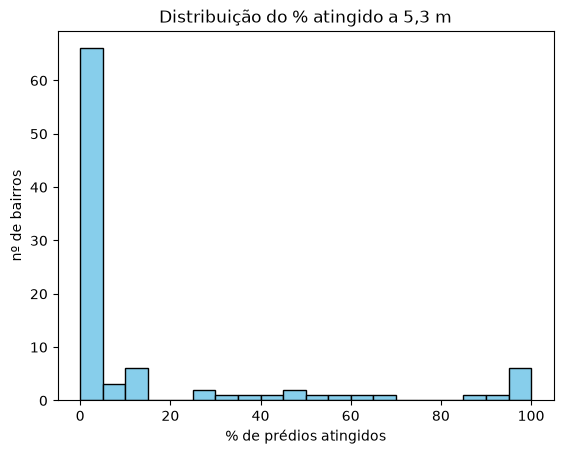

     level_key  level_m   neighborhood_raw  affected_buildings  \
2162      5_3m      5.3  Aberta dos Morros               252.0   
2163      5_3m      5.3          Agronomia                 0.0   
2164      5_3m      5.3           Anchieta               589.0   
2165      5_3m      5.3        Arquipélago              4688.0   
2166      5_3m      5.3        Auxiliadora                 0.0   
...        ...      ...                ...                 ...   
2251      5_3m      5.3      Vila Ipiranga                 0.0   
2252      5_3m      5.3        Vila Jardim                 0.0   
2253      5_3m      5.3   Vila João Pessoa                 0.0   
2254      5_3m      5.3          Vila Nova                 0.0   
2255      5_3m      5.3      Morro Santana                 0.0   

      total_buildings  percentage  population  affected_population  \
2162           4696.0         6.0      9854.0                592.0   
2163           1771.0         0.0      2677.0                  0.0 

In [22]:
n53 = df[df["level_m"] == 5.3]
n53["percentage"].plot.hist(bins=20, color="skyblue", edgecolor="black")
plt.xlabel("% de prédios atingidos"); plt.ylabel("nº de bairros")
plt.title("Distribuição do % atingido a 5,3 m")
plt.show()
print(n53)

Esta análise achamos que não ficou muito intuitiva. Um usuário, ao bater o olho, não consegue entender rapidamente o que as barras representam. Basicamente ele informa que, mesmo com um nível d'água 2 metros acima da cota de inundação do guaíba, a grande maioria de bairros não foi afetado (0% de prédios atingidos).

40 bairros nunca são atingidos até 10 m


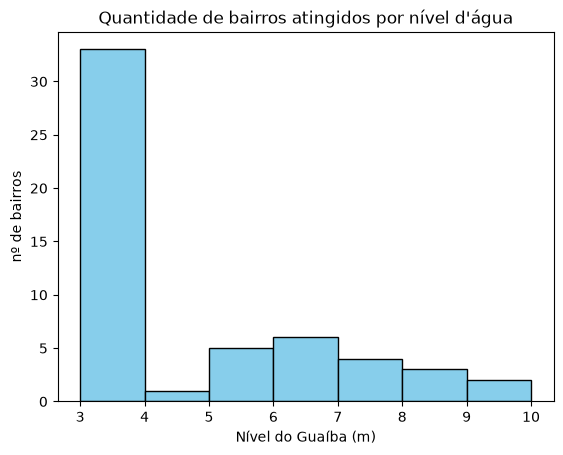

In [23]:
atingidos = df[df["affected_buildings"] > 0]
primeiro_nivel = atingidos.groupby("neighborhood")["level_m"].min()

nunca = set(df["neighborhood"]) - set(primeiro_nivel.index)
print(f"{len(nunca)} bairros nunca são atingidos até 10 m")

primeiro_nivel.plot.hist(bins=range(3, 11), color="skyblue", edgecolor="black")
plt.xlabel("Nível do Guaíba (m)"); plt.ylabel("nº de bairros")
plt.title("Quantidade de bairros atingidos por nível d'água")
plt.show()

Esta análise ficou bem mais interessante. Com ela conseguimos ter uma noção da progressão das áreas afetadas à medida que a água sobe. Percebe-se que a maior leva de bairros afetados ocorre logo no primeiro metro, entre 3,0m e 4,0m de cota, atingindo mais de 30 bairros.

## Cotas de Inundação (Prefeitura de Porto Alegre)

Agora vamos explorar os dados da base de cotas de inundação de Porto Alegre. Por se tratar de dados georeferenciados, em formato GeoJson, poderemos fazer as análises realizando plots dos polígonos para verificar as áreas afetadas.

In [28]:
import geopandas as gpd
cotas = gpd.read_parquet("./dados/processados/cotas.parquet")

cotas.crs                              # EPSG:31982, em metros: .area já sai em m²
cotas.drop(columns="geometry")         # com 25 linhas, dá para olhar a tabela inteira
cotas.geom_type.value_counts()
cotas.is_valid.all()                   # o make_valid funcionou?

np.True_

In [29]:
cotas["area_calc_ha"] = cotas.area / 10_000
(cotas["area_calc_ha"] - cotas["area_ha"]).abs().max()

np.float64(2.4251894501503557e-05)

AttributeError: _GeoPandasPolyCollection.set() got an unexpected keyword argument 'x'

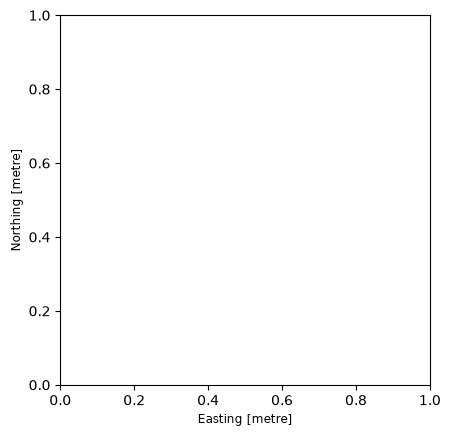

In [30]:
ax = cotas.plot(x="level_m", y="area_ha", marker="o", legend=False)
ax.set_xlabel("Nível do Guaíba (m)"); ax.set_ylabel("Área (ha)")